# 🏥 Feature Engineering Pipeline: Diabetes-130-Hospitals Dataset
**เป้าหมายของโปรเจกต์:** เตรียมข้อมูลผู้ป่วยเบาหวานให้พร้อมที่สุดสำหรับการสร้างโมเดล Machine Learning เพื่อทำนายว่า "ผู้ป่วยจะกลับมาเข้าโรงพยาบาลซ้ำภายใน 30 วันหรือไม่ (`readmit_30_days`)"

**ภาพรวมกระบวนการ (Pipeline Overview):**
1. Data Understanding (ทำความเข้าใจข้อมูล)
2. Data Cleaning & Imputation (ทำความสะอาดและจัดการค่าว่าง)
3. Advanced Feature Engineering (ปรับปรุงและสร้างตัวแปรใหม่)
4. Feature Combining & Encoding (รวมตัวแปรและเข้ารหัสข้อความ)
5. Splitting, Scaling & SMOTE (แบ่งข้อมูล ปรับสเกล และแก้ปัญหาข้อมูลไม่สมดุล)
6. Model Training (การสร้างและฝึกสอนโมเดล)
7. Model Evaluation (การวัดผลโมเดล)
8. Feature Importance (ปัจจัยที่มีผลต่อการแอดมิทซ้ำ)
9. Save Model & Scaler (บันทึกไฟล์เตรียม Deploy)

In [25]:
from sklearn.datasets import fetch_openml
import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# ดึงข้อมูล Diabetes-130-Hospitals (Dataset ID: 43874)
diabetes_data = fetch_openml(data_id=43874, as_frame=True, parser='auto')

In [4]:
# นำข้อมูลมาเก็บใน Pandas DataFrame
df = diabetes_data.frame
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (101766, 25)


,race,gender,age,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,...,change,diabetesMed,medicare,medicaid,had_emergency,had_inpatient_days,had_outpatient_days,readmitted,readmit_binary,readmit_30_days
0,Caucasian,Female,'30 years or younger',Other,Referral,1,Other,41,0,1,...,No,No,False,False,False,False,False,NO,0,0
1,Caucasian,Female,'30 years or younger','Discharged to Home',Emergency,3,Missing,59,0,18,...,Ch,Yes,False,False,False,False,False,>30,1,0
2,AfricanAmerican,Female,'30 years or younger','Discharged to Home',Emergency,2,Missing,11,5,13,...,No,Yes,False,False,False,True,True,NO,0,0
3,Caucasian,Male,'30-60 years','Discharged to Home',Emergency,2,Missing,44,1,16,...,Ch,Yes,False,False,False,False,False,NO,0,0
4,Caucasian,Male,'30-60 years','Discharged to Home',Emergency,1,Missing,51,0,8,...,Ch,Yes,False,False,False,False,False,NO,0,0


## 🔍 1. Data Understanding (การทำความเข้าใจข้อมูล)
ในขั้นตอนนี้ เราจะทำการสำรวจภาพรวมของชุดข้อมูล (Dataset) ว่ามีขนาดเท่าใด มีคอลัมน์อะไรบ้าง และตรวจสอบการกระจายตัวของข้อมูลประเภทข้อความ (Categorical)

**สิ่งที่เราค้นพบ:** ข้อมูลต้นฉบับไม่ได้ใช้ `NaN` ในการแทนค่าว่าง แต่มีการซ่อนค่าว่างไว้ในรูปของเครื่องหมาย `'?'`, `'Unknown'` หรือ `'Not Mapped'` ซึ่งเราต้องจัดการในขั้นตอนต่อไป

In [5]:
# 1. ดูภาพรวมประเภทของข้อมูลและจำนวน Non-Null เบื้องต้น
print("--- Data Info ---")
df.info()
print("\n" + "="*50 + "\n")

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 25 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   race                      101766 non-null  object  
 1   gender                    101766 non-null  object  
 2   age                       101766 non-null  object  
 3   discharge_disposition_id  101766 non-null  object  
 4   admission_source_id       101766 non-null  object  
 5   time_in_hospital          101766 non-null  int64   
 6   medical_specialty         101766 non-null  object  
 7   num_lab_procedures        101766 non-null  int64   
 8   num_procedures            101766 non-null  int64   
 9   num_medications           101766 non-null  int64   
 10  primary_diagnosis         101766 non-null  object  
 11  number_diagnoses          101766 non-null  int64   
 12  max_glu_serum             101766 non-null  object  
 13  A1Cresult  

In [6]:
# 2. เช็คค่าที่มักจะเป็น "ค่าว่างแฝง" ในคอลัมน์ที่เป็นหมวดหมู่ (Categorical)
print("--- Categorical Feature Value Counts (Top 5) ---")
for col in df.select_dtypes(include=['object', 'category']).columns:
    print(f"Feature: {col}")
    print(df[col].value_counts().head(5)) # ดูค่าที่เจอบ่อยที่สุด 5 อันดับแรก
    print("-" * 30)

--- Categorical Feature Value Counts (Top 5) ---
Feature: race
race
Caucasian          76099
AfricanAmerican    19210
Unknown             2273
Hispanic            2037
Other               1506
Name: count, dtype: int64
------------------------------
Feature: gender
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
------------------------------
Feature: age
age
'Over 60 years'          68541
'30-60 years'            30716
'30 years or younger'     2509
Name: count, dtype: int64
------------------------------
Feature: discharge_disposition_id
discharge_disposition_id
'Discharged to Home'    60234
Other                   41532
Name: count, dtype: int64
------------------------------
Feature: admission_source_id
admission_source_id
Emergency    57494
Referral     30856
Other        13416
Name: count, dtype: int64
------------------------------
Feature: medical_specialty
medical_specialty
Missing                   49949
Other       

## 🧹 2. Data Cleaning & Missing Value Imputation (การทำความสะอาดและจัดการค่าว่าง)
กระบวนการทำความสะอาดข้อมูลเพื่อป้องกันไม่ให้โมเดลเรียนรู้ข้อมูลที่ผิดพลาด:
* **แปลงค่าว่างแฝง:** เปลี่ยน `'?'` ให้เป็น `NaN` (มาตรฐานของ Pandas)
* **แปลง Binary Class:** เปลี่ยนข้อความที่มีแค่ 2 หมวด (Yes/No, True/False) ให้กลายเป็นตัวเลข `1` และ `0`
* **จัดการ Missing Values:**
  - ตัดแถวที่ระบุเพศไม่ได้ (Unknown/Invalid) ทิ้ง เนื่องจากมีจำนวนน้อยมาก
  - เติมค่าว่างในคอลัมน์ข้อมูลทั่วไป (เช่น เชื้อชาติ, ความเชี่ยวชาญแพทย์) ด้วยคำว่า `'Unknown'`
  - เติมค่าว่างในคอลัมน์ผลตรวจเลือด ด้วยคำว่า `'Not Tested'` (อิงตามหลักการทางการแพทย์)

In [7]:
# แปลงค่าว่างที่ซ่อนรูปให้เป็น NaN
missing_indicators = ['Missing', '?', 'Unknown', 'None','Unknown/Invalid']
df = df.replace(missing_indicators, np.nan)

# ตรวจสอบจำนวน Missing Values ที่แท้จริงหลังจากแปลงแล้ว
print("--- Actual Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("-" * 30)

--- Actual Missing Values ---
race                  2273
gender                   3
medical_specialty    49949
max_glu_serum        96420
A1Cresult            84748
dtype: int64
------------------------------


In [8]:
# จัดการตัวแปรเป้าหมาย (Target Variable)
# สมมติว่าเราใช้ 'readmit_30_days' เป็น Target หลัก (ควรจะเป็น 0 และ 1)
# ทำการลบคอลัมน์ Target อื่นๆ ที่จะทำให้เกิด Data Leakage ทิ้ง
columns_to_drop = ['readmitted', 'readmit_binary']
df = df.drop(columns=columns_to_drop, errors='ignore')

In [9]:
# แปลงข้อมูล Binary (Yes/No, True/False, Ch/No) ให้เป็น 0 และ 1
binary_mapping = {
    'no': 0, 'yes': 1, 'ch': 1,
    'false': 0, 'true': 1
}

binary_columns = ['change', 'diabetesMed', 'medicare', 'medicaid',
                  'had_emergency', 'had_inpatient_days', 'had_outpatient_days']

for col in binary_columns:
    if col in df.columns:
        # แปลงเป็น string -> ทำเป็นตัวพิมพ์เล็ก -> Map ค่า
        df[col] = df[col].astype(str).str.lower().str.strip().map(binary_mapping)

print("--- Data Check After Basic Encoding ---")
df[['change', 'diabetesMed', 'had_emergency']].head()

--- Data Check After Basic Encoding ---


,change,diabetesMed,had_emergency
0,0,0,0
1,1,1,0
2,0,1,0
3,1,1,0
4,1,1,0


Missing Values Imputation

In [10]:
print(f"จำนวนแถวก่อน Drop: {df.shape[0]}")

จำนวนแถวก่อน Drop: 101766


In [11]:
# ลบแถวที่ gender หายไป (แค่ 3 แถว)
df = df.dropna(subset=['gender'])

# เติมค่า race และ medical_specialty ด้วย 'Unknown'
df['race'] = df['race'].fillna('Unknown')
df['medical_specialty'] = df['medical_specialty'].fillna('Unknown')

# เติมค่าผลตรวจเลือดที่ไม่ได้ตรวจ ด้วย 'Not Tested'
df['max_glu_serum'] = df['max_glu_serum'].fillna('Not Tested')
df['A1Cresult'] = df['A1Cresult'].fillna('Not Tested')

In [12]:
print(f"จำนวนแถวหลัง Drop: {df.shape[0]}")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n--- เช็คผลลัพธ์ Binary อีกรอบ ---")
df[['change', 'diabetesMed', 'had_emergency']].head()

จำนวนแถวหลัง Drop: 101763
Series([], dtype: int64)

--- เช็คผลลัพธ์ Binary อีกรอบ ---


,change,diabetesMed,had_emergency
0,0,0,0
1,1,1,0
2,0,1,0
3,1,1,0
4,1,1,0


## ⚙️ 3. Advanced Feature Engineering (การสร้างและปรับปรุงคุณลักษณะ)
เราใช้เทคนิคทางสถิติและคณิตศาสตร์ในการปรับปรุงข้อมูลตัวเลข ให้มีความหมายและเหมาะกับโมเดลมากขึ้น:
* **Outlier Handling (Clipping):** ตัดขอบข้อมูลเวลาที่อยู่โรงพยาบาล (`time_in_hospital`) ที่เปอร์เซ็นไทล์ 99 เพื่อลดผลกระทบจากค่าที่โดดเกินไป
* **Numerical Transformation:** ปรับความเบ้ของคอลัมน์จำนวนยา (`num_medications`) ด้วย Log Transform
* **Polynomial Expansion:** สร้างตัวแปรใหม่ (`time_x_meds_poly`) จากการเอาเวลาที่อยู่ รพ. คูณกับจำนวนยา เพื่อหาความสัมพันธ์เชิงลึก
* **Statistical Operations:** หาค่าเฉลี่ยของการทำหัตถการต่อการเข้าพัก 1 ครั้ง (`avg_procedures_per_visit`)

In [13]:
# เช็คจำนวนหมวดหมู่ย่อย (Unique values) ของแต่ละคอลัมน์ที่เป็นข้อความ
print("--- จำนวนหมวดหมู่ในแต่ละคอลัมน์ ---")
cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} หมวดหมู่")

--- จำนวนหมวดหมู่ในแต่ละคอลัมน์ ---
race: 6 หมวดหมู่
gender: 2 หมวดหมู่
age: 3 หมวดหมู่
discharge_disposition_id: 2 หมวดหมู่
admission_source_id: 3 หมวดหมู่
medical_specialty: 6 หมวดหมู่
primary_diagnosis: 5 หมวดหมู่
max_glu_serum: 4 หมวดหมู่
A1Cresult: 4 หมวดหมู่
insulin: 4 หมวดหมู่


In [14]:
# ข้อมูลของ primary_diagnosis 10 อันดับแรก
print("\n--- Top 10 Primary Diagnoses (โรคที่พบบ่อยที่สุด) ---")
print(df['primary_diagnosis'].value_counts().head(10))


--- Top 10 Primary Diagnoses (โรคที่พบบ่อยที่สุด) ---
primary_diagnosis
Other                       68509
'Respiratory Issues'        14423
Diabetes                     8757
'Genitourinary Issues'       5117
'Musculoskeletal Issues'     4957
Name: count, dtype: int64


In [15]:
# ตรวจหาและจัดการ Outlier (Clipping)
p99_time = df['time_in_hospital'].quantile(0.99)
df['time_in_hospital'] = df['time_in_hospital'].clip(upper=p99_time)

# แปลงรูปตัวแปรเชิงตัวเลข (Log Transform ปรับความเบ้)
df['log_num_medications'] = np.log1p(df['num_medications'])

# ขยายตัวแบบโพลิโนเมียล (Interaction Feature)
df['time_x_meds_poly'] = df['time_in_hospital'] * df['num_medications']

# การรวมหลายคุณลักษณะด้วยการดำเนินการทางสถิติ (Mean)
df['avg_procedures_per_visit'] = df[['num_lab_procedures', 'num_procedures']].mean(axis=1)

## 🧩 4. Feature Combining & OHE (การรวมตัวแปรและการเข้ารหัส)
* **Domain Knowledge Integration:** นำคอลัมน์ย่อยๆ มาบวกกันเพื่อสร้างตัวแปรกลุ่มใหญ่ที่สื่อความหมายได้ดีกว่า เช่น `total_procedure`, `care_intensity` และ `previous_visits`
* **Drop Redundant Features:** ลบคอลัมน์ตั้งต้นที่ถูกนำไปรวมแล้วทิ้งไป เพื่อป้องกันปัญหา Multicollinearity (ตัวแปรซ้ำซ้อนจนโมเดลสับสน)
* **One-Hot Encoding (OHE):** แปลงคอลัมน์หมวดหมู่ (Categorical) ที่เหลือทั้งหมดให้เป็นตัวเลข 0 และ 1 (Dummy Variables) เพื่อให้โมเดลคอมพิวเตอร์สามารถอ่านค่าได้

In [16]:
(df.select_dtypes(include='number'))

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,change,diabetesMed,medicare,medicaid,had_emergency,had_inpatient_days,had_outpatient_days,readmit_30_days,log_num_medications,time_x_meds_poly,avg_procedures_per_visit
0,1,41,0,1,1,0,0,0,0,0,0,0,0,0.693147,1,20.5
1,3,59,0,18,9,1,1,0,0,0,0,0,0,2.944439,54,29.5
2,2,11,5,13,6,0,1,0,0,0,1,1,0,2.639057,26,8.0
3,2,44,1,16,7,1,1,0,0,0,0,0,0,2.833213,32,22.5
4,1,51,0,8,5,1,1,0,0,0,0,0,0,2.197225,8,25.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,3,51,0,16,9,1,1,1,0,0,0,0,0,2.833213,48,25.5
101762,5,33,3,18,9,0,1,1,0,0,1,0,0,2.944439,90,18.0
101763,1,53,0,9,13,1,1,1,0,0,0,1,0,2.302585,9,26.5
101764,10,45,2,21,9,1,1,1,0,0,1,0,0,3.091042,210,23.5


In [17]:
# เลือกแค่คอลัมป์ที่เป็นตัวเลข
numeric_cols = df.select_dtypes(include="number").columns
numeric_cols = numeric_cols[~numeric_cols.str.startswith("had_")]
corr = df[numeric_cols].corr(method='pearson')

# หาค่าสหสัมพันธ์ของแต่ละคอลัมป์
strong_pairs = (
    corr.where(abs(corr) > 0.5).where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack())

print(strong_pairs)

time_in_hospital     time_x_meds_poly            0.837607
num_lab_procedures   avg_procedures_per_visit    0.996312
num_medications      log_num_medications         0.934508
                     time_x_meds_poly            0.788697
change               diabetesMed                 0.506360
log_num_medications  time_x_meds_poly            0.680139
dtype: float64


In [18]:
numeric_cols

Index(['time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_diagnoses', 'change', 'diabetesMed',
       'medicare', 'medicaid', 'readmit_30_days', 'log_num_medications',
       'time_x_meds_poly', 'avg_procedures_per_visit'],
      dtype='object')

In [19]:
# สร้าง Feature ใหม่
df["total_procedure"] = df["num_lab_procedures"] + df["num_procedures"]
df["care_intensity"] = df["num_lab_procedures"] + df["num_procedures"] + df["num_medications"] + df["number_diagnoses"]
df["previous_visits"] = df["had_outpatient_days"] + df["had_emergency"] + df["had_inpatient_days"]

# Drop คอลัมน์ตั้งต้นที่ถูกนำไปบวกกันแล้วทิ้งไป
cols_to_drop = ["num_lab_procedures", "num_procedures", "had_outpatient_days",
                "had_emergency", "had_inpatient_days"]
df = df.drop(columns=cols_to_drop, errors='ignore')

# ทำ One-Hot Encoding ใหม่ เพื่อรวมทุกอย่างเข้าด้วยกัน
cat_cols_to_encode = df.select_dtypes(include=['object', 'category']).columns.tolist()
df_final = pd.get_dummies(df, columns=cat_cols_to_encode, drop_first=True, dtype=int)

print(f"--- รูปร่างข้อมูลหลังปรับแก้ ---")
print(f"จำนวนแถวและคอลัมน์: {df_final.shape}")

--- รูปร่างข้อมูลหลังปรับแก้ ---
จำนวนแถวและคอลัมน์: (101763, 43)


## ⚖️ 5. Data Splitting, Scaling & SMOTE (เตรียมพร้อมก่อนเข้าโมเดล)
ขั้นตอนสุดท้ายก่อนส่งข้อมูลให้ Machine Learning เรียนรู้:
1. **Train/Test Split:** แบ่งข้อมูลเป็นชุดฝึกสอน (Train 80%) และชุดทดสอบ (Test 20%) โดยใช้ `stratify` เพื่อให้สัดส่วนคนแอดมิทซ้ำกระจายตัวเท่ากัน
2. **Standard Scaling:** ปรับสเกลตัวเลขทั้งหมด (เช่น เวลา, จำนวนยา) ให้อยู่ในมาตรฐานเดียวกัน ป้องกันไม่ให้โมเดลให้น้ำหนักคอลัมน์ที่มีค่าตัวเลขสูงๆ มากเกินไป
3. **Handling Imbalanced Data (SMOTE):** เนื่องจากคนไข้ที่กลับมาแอดมิทซ้ำมีปริมาณน้อยมาก (Imbalanced Class) เราจึงใช้เทคนิค SMOTE สังเคราะห์ข้อมูลคลาสส่วนน้อยในชุด Train ขึ้นมาให้มีจำนวนเท่ากัน (คลาสละ 72,324 แถว) เพื่อป้องกันไม่ให้โมเดลทายลำเอียง

In [20]:
# แยก Features (X) และ Target (y)
X = df_final.drop(columns=['readmit_30_days'])
y = df_final['readmit_30_days']

# แบ่งข้อมูล Train 80% / Test 20% (ใช้ stratify เพื่อให้สัดส่วนคนแอดมิทซ้ำกระจายเท่าๆ กัน)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# เลือกเฉพาะคอลัมน์ที่เป็นตัวเลขหลักๆ (ไม่รวมพวก 0, 1 จาก One-Hot) เพื่อนำมาปรับสเกล
num_cols = ['time_in_hospital', 'num_medications', 'number_diagnoses',
            'total_procedure', 'care_intensity', 'previous_visits',
            'log_num_medications', 'time_x_meds_poly', 'avg_procedures_per_visit']

# ทำ Standard Scaling
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols]) # สำคัญมาก: Test Set ต้องใช้ .transform() เท่านั้น

print("--- แบ่งข้อมูลและปรับสเกลเสร็จสิ้น ---")
print(f"ขนาดชุดฝึกสอน (Train): {X_train.shape}")
print(f"ขนาดชุดทดสอบ (Test): {X_test.shape}")

--- แบ่งข้อมูลและปรับสเกลเสร็จสิ้น ---
ขนาดชุดฝึกสอน (Train): (81410, 42)
ขนาดชุดทดสอบ (Test): (20353, 42)


In [21]:
from imblearn.over_sampling import SMOTE

print("--- ก่อนทำ SMOTE ---")
print(y_train.value_counts())

# ใช้ SMOTE สังเคราะห์ข้อมูล
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("\n--- หลังทำ SMOTE ---")
print(y_train_balanced.value_counts())

--- ก่อนทำ SMOTE ---
readmit_30_days
0    72324
1     9086
Name: count, dtype: int64

--- หลังทำ SMOTE ---
readmit_30_days
0    72324
1    72324
Name: count, dtype: int64


## 🤖6. Model Training (การสร้างและฝึกสอนโมเดล)
ใช้ Random Forest เพราะเป็นโมเดลที่ทำงานได้ดีกับข้อมูลทางการแพทย์ ทนทานต่อ Outlier และสามารถบอกได้ว่าปัจจัยไหนสำคัญที่สุด

In [22]:
print("--- กำลังเทรนโมเดล Random Forest ---")
# กำหนด class_weight='balanced' เพื่อช่วยเรื่อง Imbalanced data
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)

# เทรนโมเดลด้วยข้อมูลที่ผ่านการทำ SMOTE แล้ว
rf_model.fit(X_train_balanced, y_train_balanced)
print("✅ เทรนโมเดลสำเร็จ!")

--- กำลังเทรนโมเดล Random Forest ---
✅ เทรนโมเดลสำเร็จ!


## 📊7. Model Evaluation (การวัดผลโมเดล)
ดูค่า Recall (ความสามารถในการจับผู้ป่วยที่จะกลับมาแอดมิทซ้ำให้ได้มากที่สุด) และ ROC-AUC Score

In [24]:
# ให้โมเดลทำนายข้อมูล Test set
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1] # เอาเฉพาะความน่าจะเป็นของคลาส 1 (กลับมาแอดมิท)

print("--- 📋 ผลการประเมินโมเดล (Classification Report) ---")
print(classification_report(y_test, y_pred))

print("--- 🎯 ค่า ROC-AUC Score ---")
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC: {auc_score:.4f}")

--- 📋 ผลการประเมินโมเดล (Classification Report) ---
              precision    recall  f1-score   support

           0       0.89      0.97      0.93     18082
           1       0.17      0.04      0.07      2271

    accuracy                           0.87     20353
   macro avg       0.53      0.51      0.50     20353
weighted avg       0.81      0.87      0.83     20353

--- 🎯 ค่า ROC-AUC Score ---
ROC-AUC: 0.5858


## 🔍8. Feature Importance (ปัจจัยที่มีผลต่อการแอดมิทซ้ำ)


/tmp/ipykernel_4240/2615268040.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances.head(10), palette='viridis')


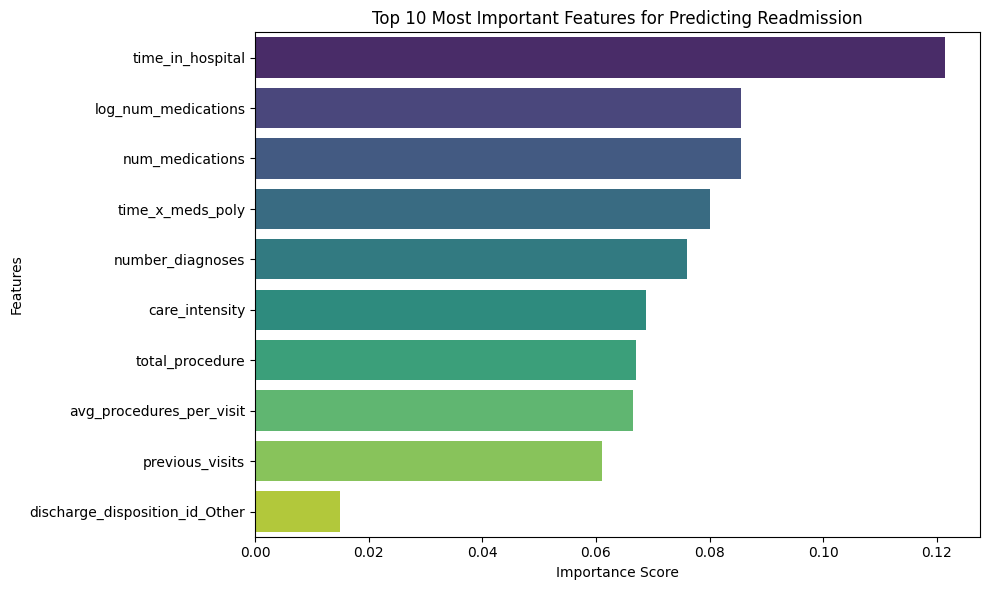

In [26]:
# สร้าง DataFrame เก็บค่าความสำคัญ
# ดึงชื่อคอลัมน์มาจากตัวแปร X_final ที่ได้จากการทำ OHE ไว้
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# พล็อต Top 10 Features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances.head(10), palette='viridis')
plt.title("Top 10 Most Important Features for Predicting Readmission")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## 💾9.Save Model & Scaler (บันทึกไฟล์เตรียม Deploy)

In [27]:
import joblib

# เซฟโมเดล
joblib.dump(rf_model, 'diabetes_rf_model.joblib')

# เซฟ Scaler (สำคัญมาก! ต้องใช้แปลงข้อมูลใหม่ที่รับมาจากหน้าเว็บ)
joblib.dump(scaler, 'diabetes_scaler.joblib')

print("✅ บันทึกไฟล์ diabetes_rf_model.joblib และ diabetes_scaler.joblib สำเร็จ!")

✅ บันทึกไฟล์ diabetes_rf_model.joblib และ diabetes_scaler.joblib สำเร็จ!


ลดขนาด model


In [28]:
from sklearn.ensemble import RandomForestClassifier
import joblib

# 1. จำกัดขนาดของโมเดล (ลดจำนวนต้นไม้และจำกัดความลึก)
rf_model = RandomForestClassifier(
    n_estimators=50,       # ลดจาก 100 เหลือ 50 ต้น
    max_depth=10,          # จำกัดความลึกไม่ให้เกิน 10 ชั้น (ช่วยลดขนาดไฟล์ได้มหาศาล)
    min_samples_split=5,   # ป้องกันไม่ให้ต้นไม้แตกกิ่งยิบย่อยเกินไป
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# เทรนโมเดลใหม่
rf_model.fit(X_train_balanced, y_train_balanced)

# 2. เซฟไฟล์แบบเปิดโหมดบีบอัด (compress=3)
joblib.dump(rf_model, 'diabetes_rf_model.joblib', compress=3)

['diabetes_rf_model.joblib']